# 🛍️ Online Retail Analytics & Customer Segmentation

## Business Problem
An online retailer has 1M+ transaction rows, but raw transactions do not say **who the most valuable customers are**.
Goal: turn raw transactions into customer-level insights.

## Main Questions
1. Who are our best customers? (RFM analysis)
2. How do customers group together? (K-Means clustering)
3. How well do we keep customers? (Cohort retention)
4. What are the sales trends? (EDA)
5. How much will customers be worth in future? (CLV)

## Machine Learning Goal
There is no target variable, so we use **unsupervised learning** (K-Means) to discover patterns.

## Table of Contents
1. Setup & Loading
2. Data Quality Check
3. Data Cleaning
4. Exploratory Data Analysis
5. RFM Analysis
6. K-Means Clustering
7. Cohort Retention
8. Pareto (80/20) Analysis
9. Customer Lifetime Value
10. Conclusions & Recommendations

## 1. Setup & Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
path = "/kaggle/input/datasets/mashlyn/online-retail-ii-uci/online_retail_II.csv"
df = pd.read_csv(path)

# Do ALL type conversions once, right after loading
df.columns = df.columns.str.strip().str.replace(" ", "_")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Invoice"] = df["Invoice"].astype(str)

print("Shape:", df.shape)
print("Unparsed dates:", df["InvoiceDate"].isna().sum())
df.head()

Shape: (1067371, 8)
Unparsed dates: 0


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer_ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 2. Data Quality Check

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer_ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [4]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "pct": (df.isna().mean() * 100).round(2),
})
missing

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer_ID,243007,22.77
Country,0,0.00


In [5]:
print("Duplicate rows:", df.duplicated().sum())
df.describe()

Duplicate rows: 34335


,Quantity,InvoiceDate,Price,Customer_ID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394028544,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


**Findings:** `Customer_ID` is missing in ~22.8% of rows (guest checkouts), there are duplicate rows,
and `Quantity` / `Price` contain negative values (returns, cancellations, accounting adjustments).

## 3. Data Cleaning
Steps: drop duplicates → remove cancelled invoices → keep positive quantity & price →
remove non-product codes → **net out cancelled orders** → create Revenue.

In [6]:
df = df.drop_duplicates()

cancelled = df[df["Invoice"].str.startswith("C")]
print("Cancelled rows:", len(cancelled))

clean = df[
    (~df["Invoice"].str.startswith("C"))
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
].copy()

non_products = ["POST", "DOT", "M", "BANK CHARGES", "AMAZONFEE", "CRUK"]
clean = clean[~clean["StockCode"].astype(str).isin(non_products)]
clean["Revenue"] = clean["Quantity"] * clean["Price"]
print("After basic cleaning:", clean.shape)

Cancelled rows: 19104
After basic cleaning: (1003764, 9)


### Net out cancelled orders
Customer 16446 placed one order of 80,995 units (£168k) that was **cancelled the next day**.
Removing only the cancellation rows leaves the original sale in the data and inflates revenue.
We remove sale lines that have a matching cancellation (same customer, product and quantity).
*Simplification:* the whole sale line is dropped even when only part of it was returned.

In [7]:
returns = df[df["Invoice"].str.startswith("C") & df["Customer_ID"].notna()].copy()
returns["Quantity"] = returns["Quantity"].abs()
returns = returns[["Customer_ID", "StockCode", "Quantity"]].drop_duplicates()
returns["was_returned"] = True

def net_returns(data):
    tmp = data.merge(returns, on=["Customer_ID", "StockCode", "Quantity"], how="left")
    return tmp[tmp["was_returned"].isna()].drop(columns="was_returned")

clean_net = net_returns(clean)
print("Rows removed by netting:", len(clean) - len(clean_net))

clean = clean_net.copy()

customers = clean.dropna(subset=["Customer_ID"]).copy()
customers["Customer_ID"] = customers["Customer_ID"].astype(int)

print("clean (all sales):", clean.shape)
print("customers (with ID):", customers.shape)

# Sanity check: the cancelled order should be gone
print("Customer 16446 rows left:", (customers["Customer_ID"] == 16446).sum())

Rows removed by netting: 12781
clean (all sales): (990983, 9)
customers (with ID): (764113, 9)
Customer 16446 rows left: 2


## 4. Exploratory Data Analysis

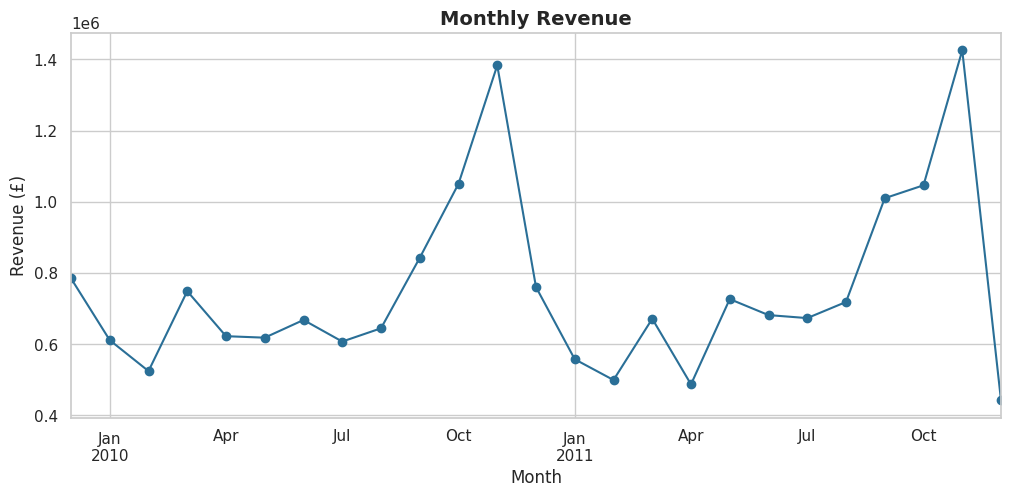

In [8]:
clean["Month"] = clean["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
monthly = clean.groupby("Month")["Revenue"].sum()

fig, ax = plt.subplots(figsize=(12, 5))
monthly.plot(ax=ax, marker="o", color="#2a6f97")
ax.set_title("Monthly Revenue", fontsize=14, weight="bold")
ax.set_ylabel("Revenue (£)")
plt.show()

In [9]:
print(clean.groupby("Country")["Revenue"].sum().nlargest(10))
print()
print(clean.groupby("Description")["Revenue"].sum().nlargest(10))

Country
United Kingdom   16,075,045.30
EIRE                583,679.90
Netherlands         538,047.87
Germany             378,250.38
France              294,153.48
Australia           166,353.20
Switzerland          92,711.58
Sweden               82,209.04
Spain                81,055.17
Denmark              63,427.79
Name: Revenue, dtype: float64

Description
REGENCY CAKESTAND 3 TIER             310,698.22
WHITE HANGING HEART T-LIGHT HOLDER   240,240.27
PARTY BUNTING                        146,756.23
JUMBO BAG RED RETROSPOT              140,184.23
ASSORTED COLOUR BIRD ORNAMENT        128,428.74
PAPER CHAIN KIT 50'S CHRISTMAS       115,337.59
CHILLI LIGHTS                         79,756.98
RABBIT NIGHT LIGHT                    66,732.75
JUMBO BAG STRAWBERRY                  66,310.45
BLACK RECORD COVER FRAME              65,099.29
Name: Revenue, dtype: float64


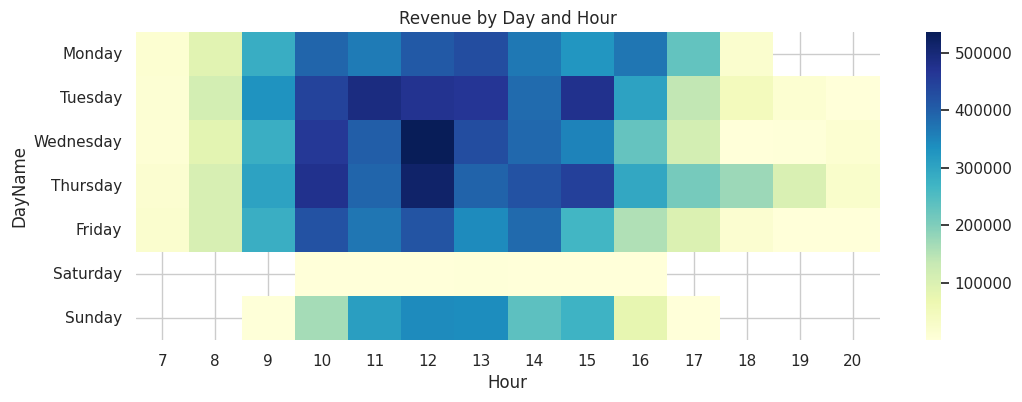

In [10]:
clean["Hour"] = clean["InvoiceDate"].dt.hour
clean["DayName"] = clean["InvoiceDate"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = clean.pivot_table(index="DayName", columns="Hour", values="Revenue", aggfunc="sum").reindex(
    [d for d in day_order if d in clean["DayName"].unique()]
)

plt.figure(figsize=(12, 4))
sns.heatmap(pivot, cmap="YlGnBu")
plt.title("Revenue by Day and Hour")
plt.show()

**Key insight:** revenue peaks in autumn (Christmas stocking), the UK dominates sales,
and trading is concentrated in the mid-day hours.

## 5. RFM Analysis
* **Recency** – days since last purchase (lower is better)
* **Frequency** – number of distinct invoices
* **Monetary** – total spend

In [11]:
snapshot_date = customers["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customers.groupby("Customer_ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm["R"] + rfm["F"] + rfm["M"]

def segment(row):
    if row["R"] >= 4 and row["F"] >= 4:
        return "Champions"
    elif row["R"] >= 3 and row["F"] >= 3:
        return "Loyal Customers"
    elif row["R"] >= 4 and row["F"] <= 2:
        return "New Customers"
    elif row["R"] <= 2 and row["F"] >= 3:
        return "At Risk"
    elif row["R"] <= 2 and row["F"] <= 2:
        return "Lost"
    else:
        return "Need Attention"

rfm["Segment"] = rfm.apply(segment, axis=1)

rfm_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum"),
).sort_values("Total_Revenue", ascending=False)

rfm_summary["Pct_Customers"] = rfm_summary["Customers"] / rfm_summary["Customers"].sum() * 100
rfm_summary["Pct_Revenue"] = rfm_summary["Total_Revenue"] / rfm_summary["Total_Revenue"].sum() * 100
rfm_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Pct_Customers,Pct_Revenue
Segment,,,,,,,
Champions,1476,20.41,15.34,"7,733.38","11,414,466.91",25.27,70.40
Loyal Customers,1204,78.91,5.30,"1,932.94","2,327,256.21",20.62,14.35
At Risk,824,369.76,4.92,"1,706.81","1,406,411.95",14.11,8.67
Lost,1512,457.47,1.25,409.65,"619,398.21",25.89,3.82
New Customers,449,28.14,1.46,547.30,"245,739.18",7.69,1.52
Need Attention,375,107.35,1.36,531.73,"199,399.22",6.42,1.23


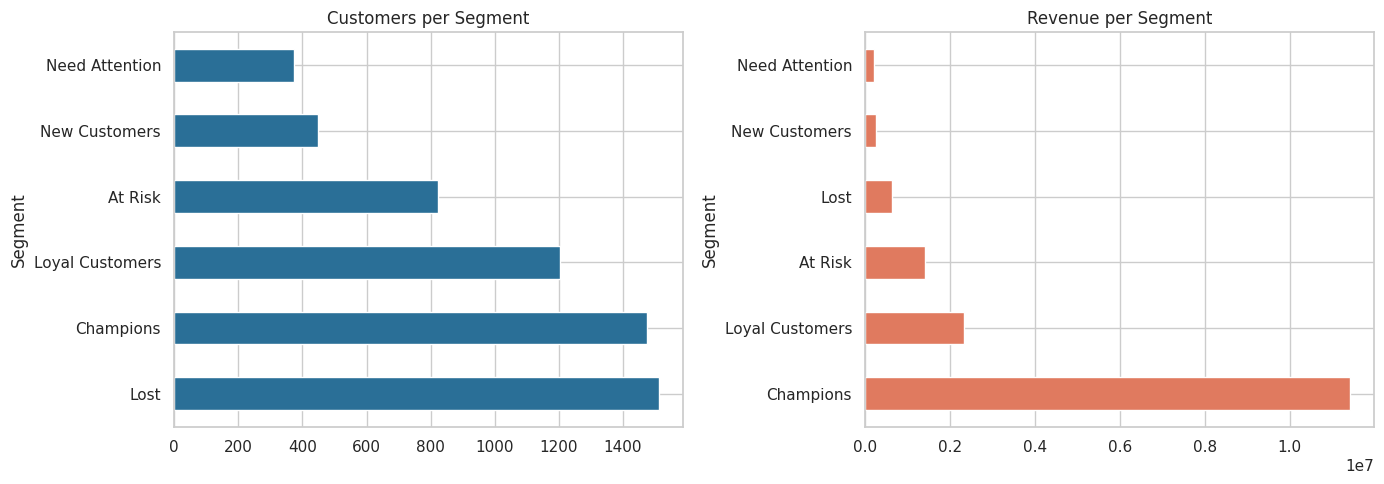

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rfm["Segment"].value_counts().plot(kind="barh", ax=axes[0], color="#2a6f97")
axes[0].set_title("Customers per Segment")
rfm_summary["Total_Revenue"].plot(kind="barh", ax=axes[1], color="#e07a5f")
axes[1].set_title("Revenue per Segment")
plt.tight_layout()
plt.show()

## 6. K-Means Clustering
RFM data is heavily skewed, so we **log-transform** (`log1p`) and then **standardize** before clustering.

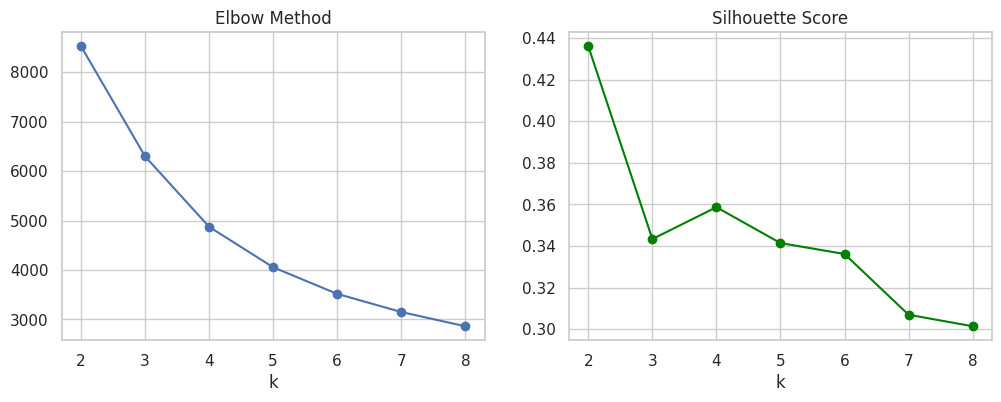

{2: np.float64(0.436), 3: np.float64(0.343), 4: np.float64(0.359), 5: np.float64(0.341), 6: np.float64(0.336), 7: np.float64(0.307), 8: np.float64(0.301)}


In [13]:
X = rfm[["Recency", "Frequency", "Monetary"]]
X_log = np.log1p(X)
X_scaled = StandardScaler().fit_transform(X_log)

inertia, sil = [], []
ks = range(2, 9)
for k in ks:
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km_k.inertia_)
    sil.append(silhouette_score(X_scaled, km_k.labels_, sample_size=3000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, marker="o", color="green"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k")
plt.show()

print(dict(zip(ks, np.round(sil, 3))))

**Choice of k:** k = 4 balances the elbow in the inertia curve with a good silhouette score and gives
four segments that are easy to explain to a business team.

In [14]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = km.fit_predict(X_scaled)

cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum"),
).round(1)
cluster_profile["Pct_Customers"] = (cluster_profile["Customers"] / cluster_profile["Customers"].sum() * 100).round(1)
cluster_profile["Pct_Revenue"] = (cluster_profile["Total_Revenue"] / cluster_profile["Total_Revenue"].sum() * 100).round(1)
cluster_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Pct_Customers,Pct_Revenue
Cluster,,,,,,,
0,1963,395.00,1.40,312.10,"612,717.40",33.60,3.80
1,1449,228.20,5.00,"1,826.90","2,647,208.60",24.80,16.30
2,1174,27.80,19.00,"10,141.20","11,905,766.20",20.10,73.40
3,1254,28.40,3.00,834.90,"1,046,979.50",21.50,6.50


### Name clusters by behaviour (not by cluster number)
Rules, so names stay correct whatever the cluster numbers are:
* highest Avg_Frequency → **VIPs**
* highest Avg_Recency (longest inactive) → **Lost / One-time buyers**
* of the remaining two: more recent → **Promising**, less recent → **At Risk**

In [15]:
prof = cluster_profile.copy()
vip = prof["Avg_Frequency"].idxmax()
lost = prof["Avg_Recency"].idxmax()
rest = prof.drop(index=[vip, lost])
promising = rest["Avg_Recency"].idxmin()
at_risk = rest["Avg_Recency"].idxmax()

cluster_map = {
    vip: "VIPs (frequent, high value, recent)",
    promising: "Promising (recent, growing)",
    at_risk: "At Risk (valuable but lapsing)",
    lost: "Lost / One-time buyers",
}
rfm["Cluster_Name"] = rfm["Cluster"].map(cluster_map)

named_profile = cluster_profile.rename(index=cluster_map)
named_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Pct_Customers,Pct_Revenue
Cluster,,,,,,,
Lost / One-time buyers,1963,395.00,1.40,312.10,"612,717.40",33.60,3.80
At Risk (valuable but lapsing),1449,228.20,5.00,"1,826.90","2,647,208.60",24.80,16.30
"VIPs (frequent, high value, recent)",1174,27.80,19.00,"10,141.20","11,905,766.20",20.10,73.40
"Promising (recent, growing)",1254,28.40,3.00,834.90,"1,046,979.50",21.50,6.50


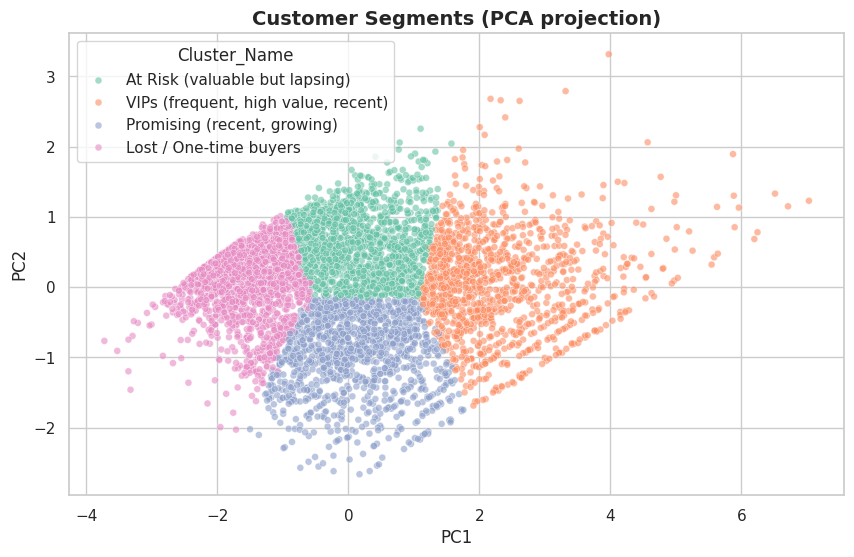

Variance explained: 0.95


In [16]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
rfm["PC1"], rfm["PC2"] = coords[:, 0], coords[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm, x="PC1", y="PC2", hue="Cluster_Name", palette="Set2", alpha=0.6, s=25)
plt.title("Customer Segments (PCA projection)", fontsize=14, weight="bold")
plt.show()

print("Variance explained:", pca.explained_variance_ratio_.sum().round(2))

## 7. Cohort Retention
Group customers by the month of their **first** purchase and track the share who return in later months.

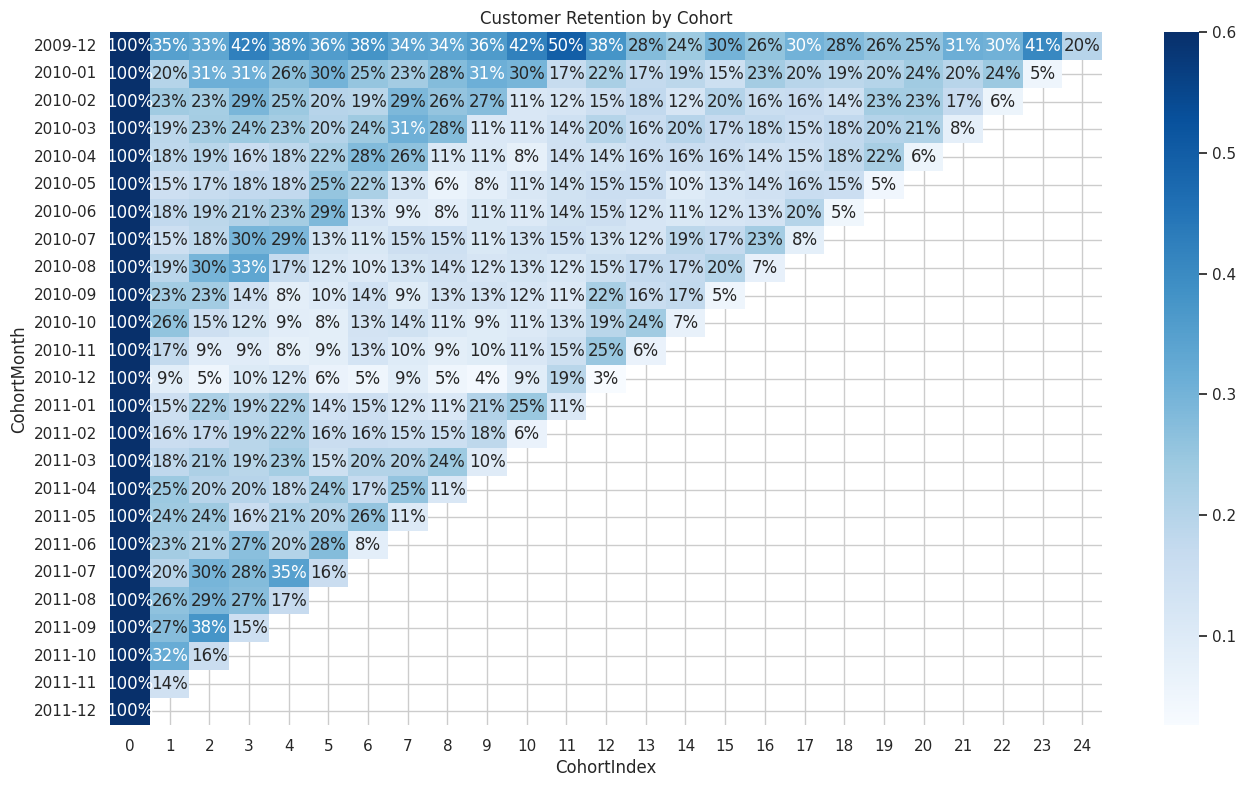

Average month-1 retention: 20.8%
Average month-6 retention: 17.8%


In [17]:
customers["OrderMonth"] = customers["InvoiceDate"].dt.to_period("M")
customers["CohortMonth"] = (
    customers.groupby("Customer_ID")["InvoiceDate"].transform("min").dt.to_period("M")
)
customers["CohortIndex"] = (
    (customers["OrderMonth"].dt.year - customers["CohortMonth"].dt.year) * 12
    + (customers["OrderMonth"].dt.month - customers["CohortMonth"].dt.month)
)

cohort_data = (
    customers.groupby(["CohortMonth", "CohortIndex"])["Customer_ID"].nunique().reset_index()
)
cohort_counts = cohort_data.pivot(index="CohortMonth", columns="CohortIndex", values="Customer_ID")
retention = cohort_counts.divide(cohort_counts.iloc[:, 0], axis=0)

plt.figure(figsize=(16, 9))
sns.heatmap(retention, annot=True, fmt=".0%", cmap="Blues", vmax=0.6)
plt.title("Customer Retention by Cohort")
plt.show()

print(f"Average month-1 retention: {retention[1].mean():.1%}")
print(f"Average month-6 retention: {retention[6].mean():.1%}")

## 8. Pareto (80/20) Analysis

Top 20% of customers generate 76% of revenue


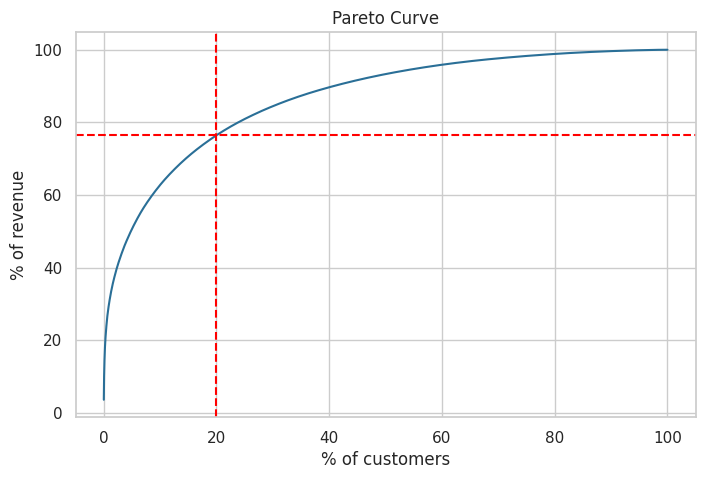

In [18]:
sorted_rev = rfm["Monetary"].sort_values(ascending=False)
cum_pct = sorted_rev.cumsum() / sorted_rev.sum()
cust_pct = np.arange(1, len(sorted_rev) + 1) / len(sorted_rev)

top20 = cum_pct[cust_pct <= 0.20].iloc[-1]
print(f"Top 20% of customers generate {top20:.0%} of revenue")

plt.figure(figsize=(8, 5))
plt.plot(cust_pct * 100, cum_pct.values * 100, color="#2a6f97")
plt.axvline(20, color="red", ls="--")
plt.axhline(top20 * 100, color="red", ls="--")
plt.xlabel("% of customers")
plt.ylabel("% of revenue")
plt.title("Pareto Curve")
plt.show()

## 9. Customer Lifetime Value (BG/NBD + Gamma-Gamma)
`lifetimes` definitions: **frequency** = repeat purchases (orders − 1), **recency** = days between first
and last purchase, **T** = customer age. These differ from RFM recency.

In [19]:
%pip install -q lifetimes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 17.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [20]:
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data

clv_df = summary_data_from_transaction_data(
    customers, "Customer_ID", "InvoiceDate",
    monetary_value_col="Revenue", observation_period_end=snapshot_date,
)
clv_df = clv_df[clv_df["monetary_value"] > 0]

bgf = BetaGeoFitter(penalizer_coef=0.01).fit(clv_df["frequency"], clv_df["recency"], clv_df["T"])
clv_df["pred_purchases_90d"] = bgf.predict(90, clv_df["frequency"], clv_df["recency"], clv_df["T"])

# Gamma-Gamma needs repeat buyers only
repeat = clv_df[clv_df["frequency"] > 0].copy()
ggf = GammaGammaFitter(penalizer_coef=0.01).fit(repeat["frequency"], repeat["monetary_value"])
repeat["clv_6m"] = ggf.customer_lifetime_value(
    bgf, repeat["frequency"], repeat["recency"], repeat["T"], repeat["monetary_value"],
    time=6, freq="D", discount_rate=0.01,
)
repeat.sort_values("clv_6m", ascending=False).head(10)

,frequency,recency,T,monetary_value,pred_purchases_90d,clv_6m
Customer_ID,,,,,,
18102,66.00,738.00,739.00,"8,740.04",7.23,"122,040.34"
14646,89.00,736.00,738.00,"5,724.00",9.72,"107,288.49"
17450,29.00,430.00,439.00,"6,669.47",5.07,"65,335.90"
14156,114.00,729.00,739.00,"2,571.85",12.37,"61,349.11"
14096,16.00,97.00,102.00,"3,327.99",7.76,"49,836.87"
14911,244.00,737.00,739.00,979.95,26.36,"49,775.74"
12415,17.00,503.00,528.00,"8,287.52",2.62,"42,121.31"
13694,80.00,732.00,736.00,"2,329.15",8.77,"39,398.99"
17511,50.00,735.00,738.00,"2,974.28",5.52,"31,714.66"


**Sanity check:** customer 16446 (the cancelled £168k order) should no longer be at the top.

## 10. Conclusions & Recommendations
*(Fill in the X / Y values from your own outputs above.)*

1. **Pareto:** top 20% of customers generate ~X% of revenue → build a VIP loyalty program.
2. **Retention:** only ~Y% of customers return in month 1 → send a re-engagement email around day 30.
3. **Seasonality:** revenue peaks in autumn → stock up and start campaigns before September.
4. **At Risk (RFM) / At Risk cluster (K-Means):** valuable customers who went quiet → targeted win-back offer.
5. **Promising customers:** recent with few orders → second-purchase incentive.
6. **Lost customers:** large in number but small in revenue → low-cost automated campaigns only.

### Limitations
* ~22.8% of rows had no Customer ID and were excluded from customer-level analysis.
* Duplicate rows were dropped; cancellations were netted out approximately (whole line).
* Only two years of data, so annual seasonality is seen just twice.